In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train (1).csv


In [7]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [9]:
print("Shape of Dataset:", df.shape)

Shape of Dataset: (1460, 81)


In [12]:
df.head()
df.head(10)
df.head(3)
df.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [14]:
missing = df.isnull().sum()

print(missing)

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


In [15]:
print(missing[missing > 0])

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage[missing_percentage > 0])

LotFrontage     17.739726
Alley           93.767123
MasVnrType      59.726027
MasVnrArea       0.547945
BsmtQual         2.534247
BsmtCond         2.534247
BsmtExposure     2.602740
BsmtFinType1     2.534247
BsmtFinType2     2.602740
Electrical       0.068493
FireplaceQu     47.260274
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
PoolQC          99.520548
Fence           80.753425
MiscFeature     96.301370
dtype: float64


Initial Dataset Observations:
1. The dataset contains 1460 rows and 81 columns.
2. The dataset contains numerical and categorical features.
3. Some columns contain missing values.
4. Missing values need to be investigated before data cleaning.

In [17]:
numerical_columns = df.select_dtypes(include=np.number).columns

categorical_columns = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'Fireplac

In [18]:
ordinal_columns = [
    'OverallQual',
    'OverallCond',
    'ExterQual',
    'KitchenQual'
]

print("Ordinal Variables:")
print(ordinal_columns)

Ordinal Variables:
['OverallQual', 'OverallCond', 'ExterQual', 'KitchenQual']


In [19]:
df['SalePrice'].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


In [20]:
print("Mean:", df['SalePrice'].mean())

print("Median:", df['SalePrice'].median())

print("Mode:", df['SalePrice'].mode()[0])

Mean: 180921.19589041095
Median: 163000.0
Mode: 140000


In [21]:

variance = df['SalePrice'].var()


data_range = df['SalePrice'].max() - df['SalePrice'].min()


Q1 = df['SalePrice'].quantile(0.25)
Q3 = df['SalePrice'].quantile(0.75)
IQR = Q3 - Q1

print("Variance:", variance)
print("Range:", data_range)
print("IQR:", IQR)

Variance: 6311111264.297451
Range: 720100
IQR: 84025.0


In [22]:
skewness = df['SalePrice'].skew()

kurtosis = df['SalePrice'].kurt()

print("Skewness:", skewness)
print("Kurtosis:", kurtosis)

Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529


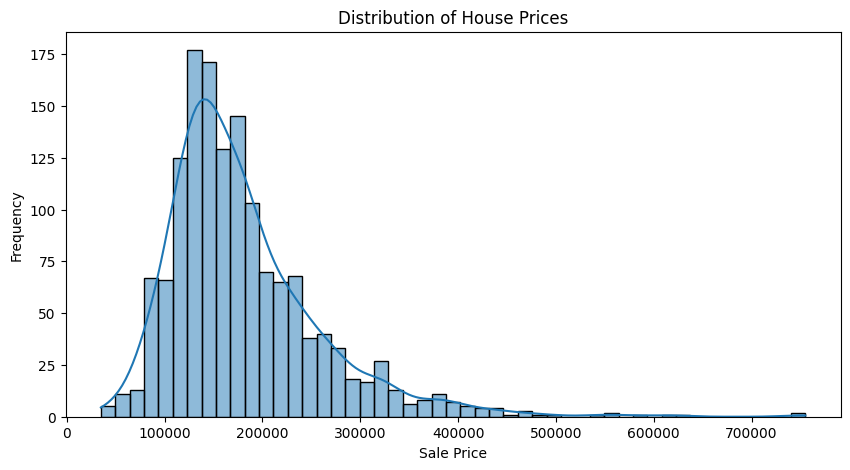

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(df['SalePrice'], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

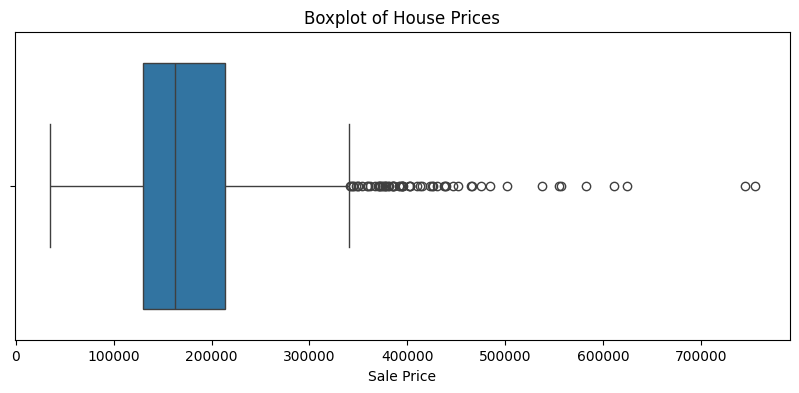

In [24]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['SalePrice'])

plt.title("Boxplot of House Prices")
plt.xlabel("Sale Price")

plt.show()

The boxplot shows the distribution of house prices.
It helps identify the median, spread of prices,
and possible outliers in the dataset.

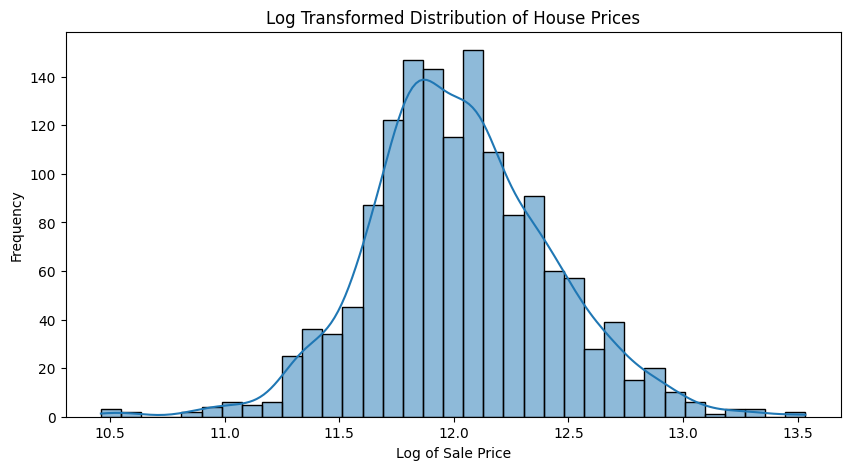

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(df['SalePrice']), kde=True)

plt.title("Log Transformed Distribution of House Prices")
plt.xlabel("Log of Sale Price")
plt.ylabel("Frequency")

plt.show()

The countplot displays the number of houses
belonging to different house styles.
It helps identify the most and least common
house styles in the dataset.

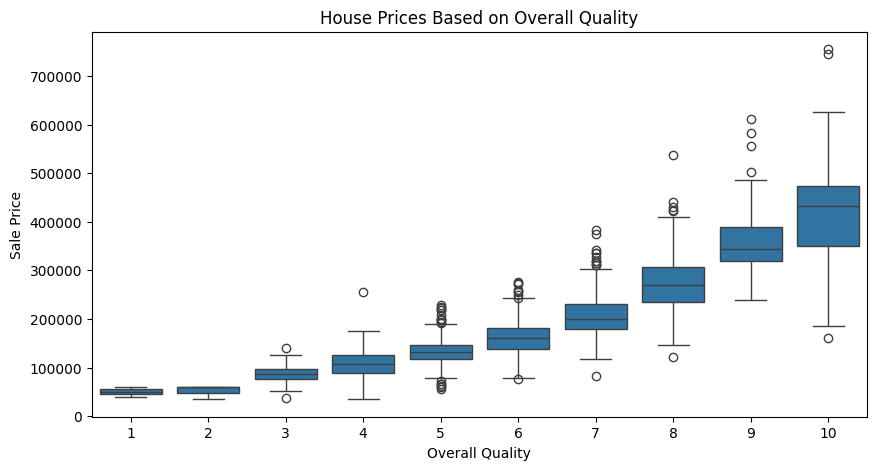

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(x='OverallQual', y='SalePrice', data=df)

plt.title("House Prices Based on Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

The boxplot shows that house prices generally
increase with overall quality. This indicates
a positive relationship between house quality
and selling price.

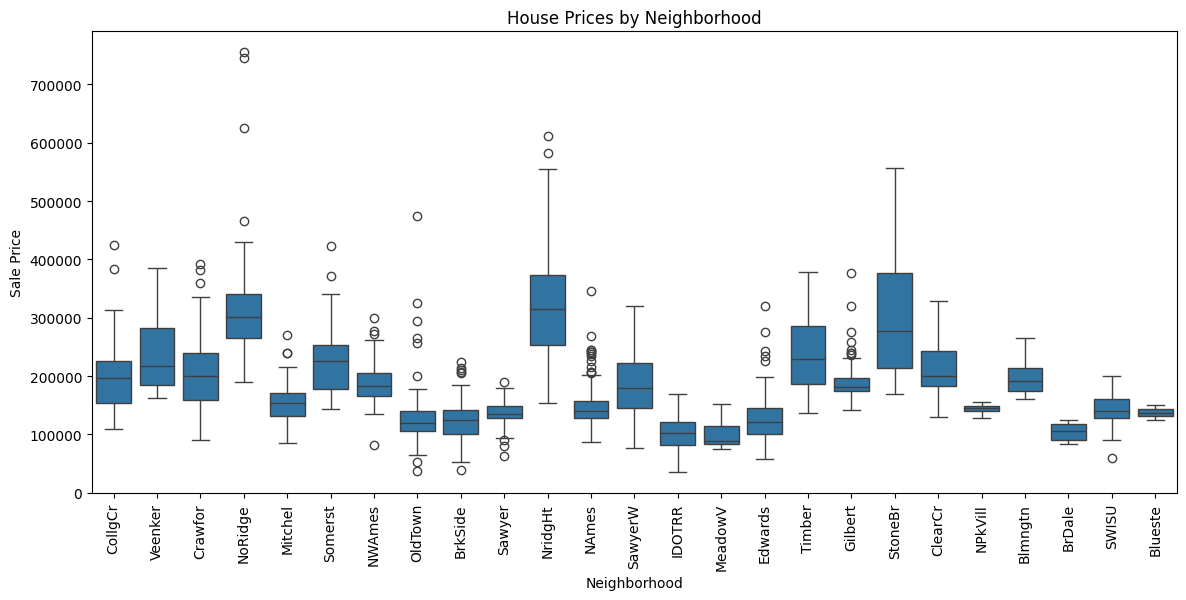

In [27]:
plt.figure(figsize=(14, 6))

sns.boxplot(x='Neighborhood', y='SalePrice', data=df)

plt.title("House Prices by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")

plt.xticks(rotation=90)

plt.show()

The boxplot shows variations in house prices
across different neighborhoods. Location plays
an important role in determining house prices.

In [28]:
correlation = df.select_dtypes(include=np.number).corr()

print(correlation['SalePrice'].sort_values(ascending=False))

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

In [29]:
top_10_corr = correlation['SalePrice'].sort_values(
    ascending=False
).head(11)

print(top_10_corr)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


In [30]:
covariance = df.select_dtypes(include=np.number).cov()

print("Covariance with SalePrice:")
print(covariance['SalePrice'].sort_values(ascending=False))

Covariance with SalePrice:
SalePrice        6.311111e+09
LotArea          2.092111e+08
GrLivArea        2.958187e+07
TotalBsmtSF      2.138442e+07
1stFlrSF         1.860663e+07
BsmtFinSF1       1.400137e+07
2ndFlrSF         1.107415e+07
GarageArea       1.058910e+07
BsmtUnfSF        7.528864e+06
MasVnrArea       6.854858e+06
WoodDeckSF       3.230258e+06
OpenPorchSF      1.662523e+06
YearBuilt        1.254637e+06
GarageYrBlt      9.489296e+05
YearRemodAdd     8.317079e+05
LotFrontage      7.124262e+05
ScreenPorch      4.936535e+05
PoolArea         2.949323e+05
3SsnPorch        1.038372e+05
OverallQual      8.690413e+04
TotRmsAbvGrd     6.891717e+04
GarageCars       3.802018e+04
FullBath         2.453808e+04
Fireplaces       2.391325e+04
HalfBath         1.135024e+04
BedroomAbvGr     1.090147e+04
MoSold           9.972849e+03
BsmtFullBath     9.362786e+03
BsmtHalfBath    -3.194849e+02
KitchenAbvGr    -2.378952e+03
YrSold          -3.051541e+03
OverallCond     -6.882739e+03
LowQualFinSF 

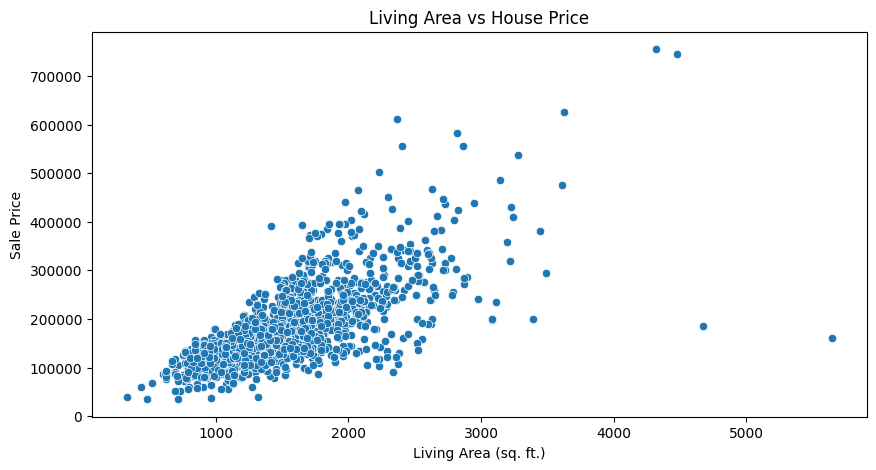

In [31]:
plt.figure(figsize=(10, 5))

sns.scatterplot(x='GrLivArea', y='SalePrice', data=df)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (sq. ft.)")
plt.ylabel("Sale Price")

plt.show()

The scatter plot shows a positive relationship
between living area and house price. Generally,
houses with larger living areas have higher
selling prices.

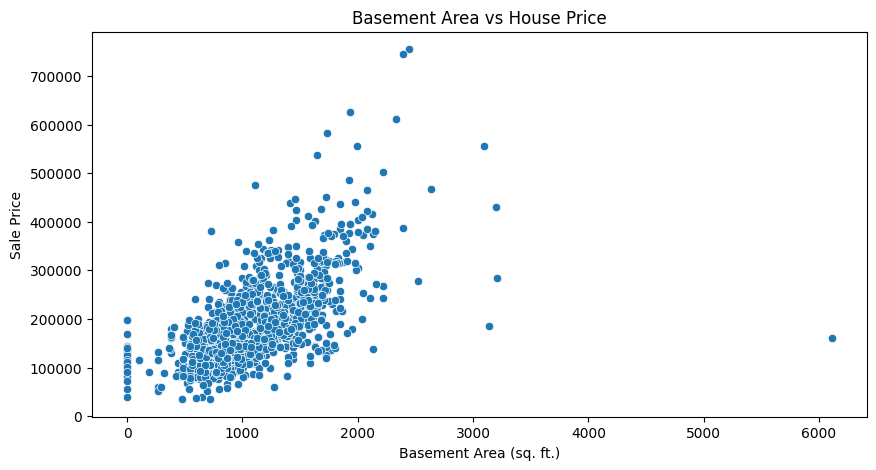

In [32]:
plt.figure(figsize=(10, 5))

sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=df)

plt.title("Basement Area vs House Price")
plt.xlabel("Basement Area (sq. ft.)")
plt.ylabel("Sale Price")

plt.show()

The scatter plot indicates a generally positive
relationship between basement area and house price.
However, prices also depend on other features.

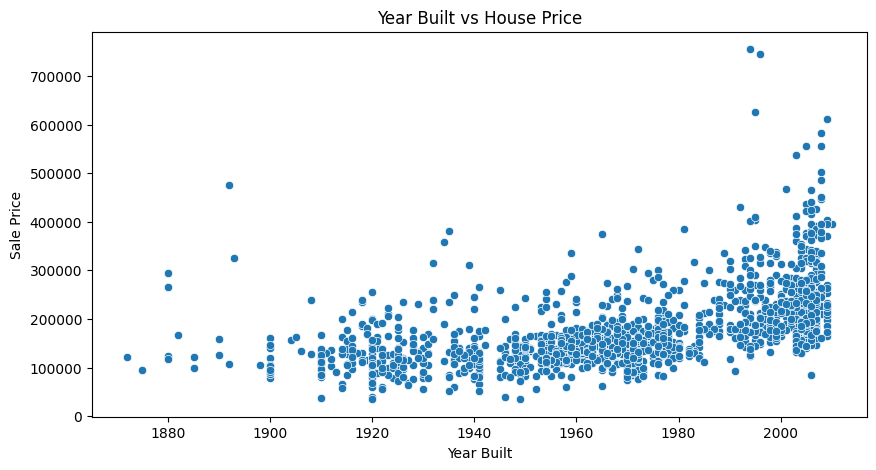

In [33]:
plt.figure(figsize=(10, 5))

sns.scatterplot(x='YearBuilt', y='SalePrice', data=df)

plt.title("Year Built vs House Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()

The scatter plot shows the relationship between
construction year and house price. Newer houses
generally tend to have higher selling prices,
although there are some variations.

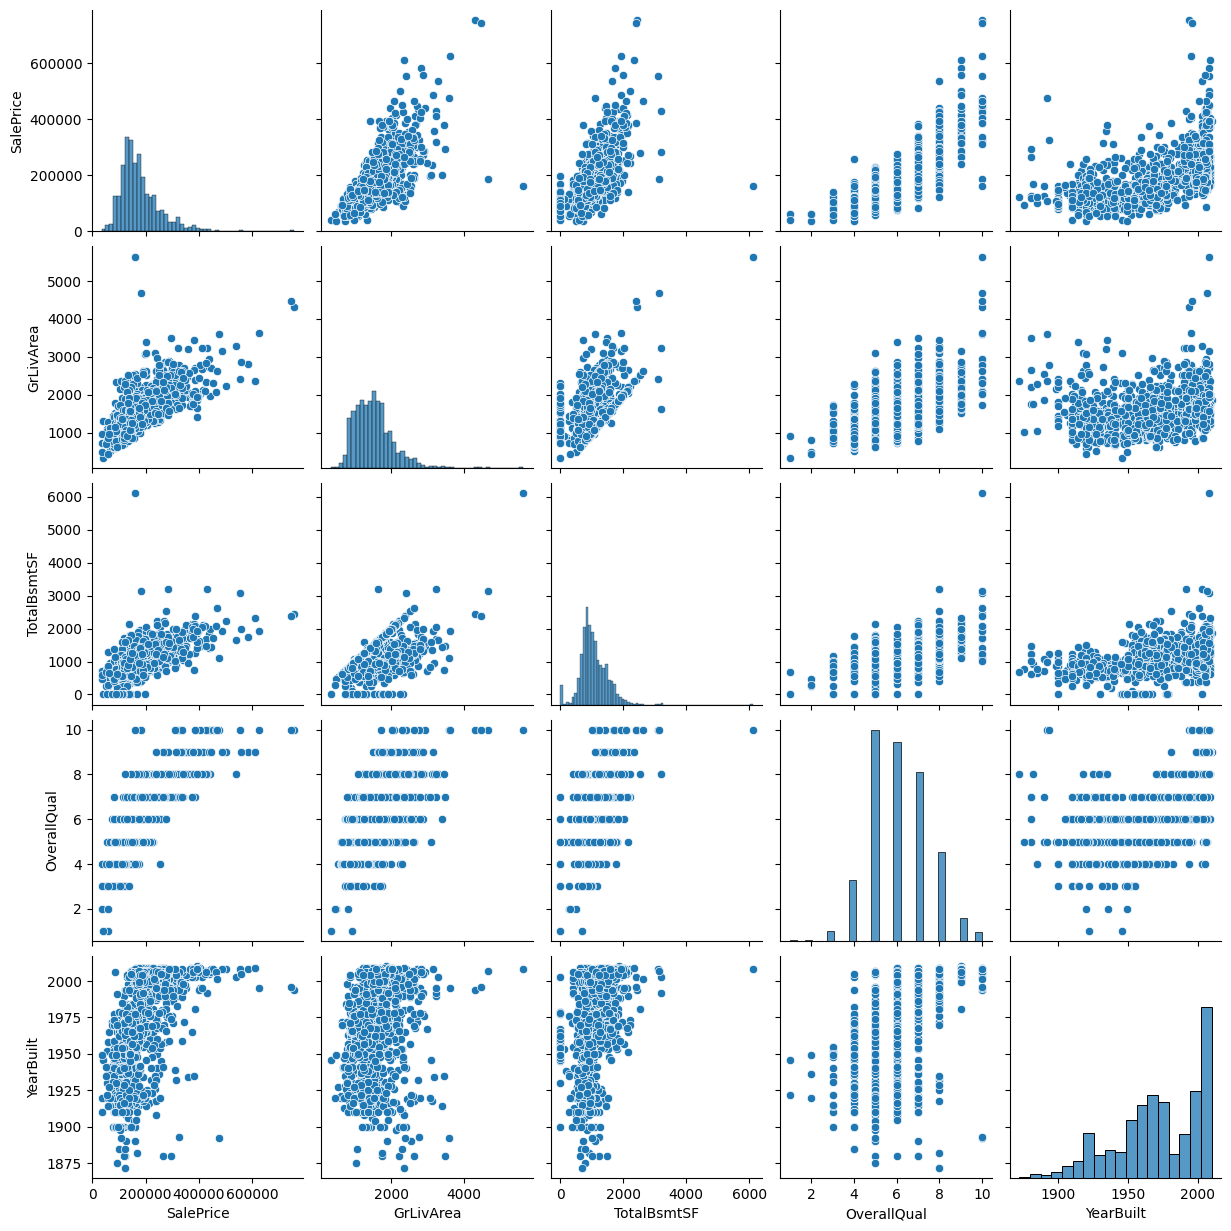

In [34]:
selected_columns = [
    'SalePrice',
    'GrLivArea',
    'TotalBsmtSF',
    'OverallQual',
    'YearBuilt'
]

sns.pairplot(df[selected_columns])

plt.show()

The pairplot helps visualize relationships
between multiple numerical variables.
It shows that living area and overall quality
have positive relationships with house price.

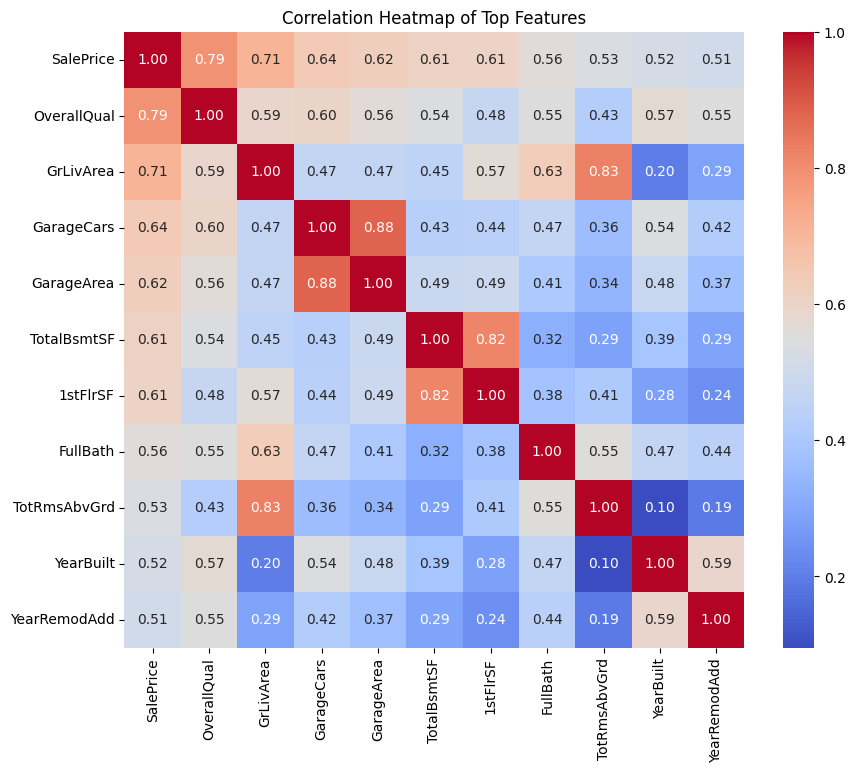

In [35]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation[top_10_corr.index].loc[top_10_corr.index],
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Top Features")

plt.show()

In [36]:
Q1 = df['SalePrice'].quantile(0.25)
Q3 = df['SalePrice'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['SalePrice'] < lower_limit) |
    (df['SalePrice'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))

Lower Limit: 3937.5
Upper Limit: 340037.5
Number of Outliers: 61


In [37]:
z_scores = np.abs(stats.zscore(df['SalePrice']))

z_outliers = df[z_scores > 3]

print("Number of Z-Score Outliers:", len(z_outliers))

Number of Z-Score Outliers: 22


In [38]:
iqr_count = len(outliers)
z_count = len(z_outliers)

print("IQR Outliers:", iqr_count)
print("Z-Score Outliers:", z_count)

IQR Outliers: 61
Z-Score Outliers: 22


In [39]:
common_outliers = set(outliers.index).intersection(
    set(z_outliers.index)
)

print("Common Outliers:", len(common_outliers))

Common Outliers: 22


IQR and Z-score methods were used to detect
outliers in house prices. Both methods may
identify different numbers of unusual values.
The results help us understand the distribution
of house prices.

In [40]:
duplicates = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicates)

Number of Duplicate Rows: 0


In [41]:
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Percentage', ascending=False)

print(missing_summary)

              Missing Values  Percentage
PoolQC                  1453   99.520548
MiscFeature             1406   96.301370
Alley                   1369   93.767123
Fence                   1179   80.753425
MasVnrType               872   59.726027
FireplaceQu              690   47.260274
LotFrontage              259   17.739726
GarageType                81    5.547945
GarageYrBlt               81    5.547945
GarageFinish              81    5.547945
GarageQual                81    5.547945
GarageCond                81    5.547945
BsmtExposure              38    2.602740
BsmtFinType2              38    2.602740
BsmtQual                  37    2.534247
BsmtCond                  37    2.534247
BsmtFinType1              37    2.534247
MasVnrArea                 8    0.547945
Electrical                 1    0.068493


Missing values were identified in different
columns of the dataset. Some missing values
represent unavailable house features, while
others may require further investigation.

In [47]:
print("House prices:")
print(df['SalePrice'].describe())

print("\nHouse construction years:")
print(df['YearBuilt'].describe())

print("\nHouse quality ratings:")
print(df['OverallQual'].value_counts().sort_index())

House prices:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

House construction years:
count    1460.000000
mean     1971.267808
std        30.202904
min      1872.000000
25%      1954.000000
50%      1973.000000
75%      2000.000000
max      2010.000000
Name: YearBuilt, dtype: float64

House quality ratings:
OverallQual
1       2
2       3
3      20
4     116
5     397
6     374
7     319
8     168
9      43
10     18
Name: count, dtype: int64


Data consistency checks were performed on
house prices, construction years and quality
ratings to identify unusual or invalid values.

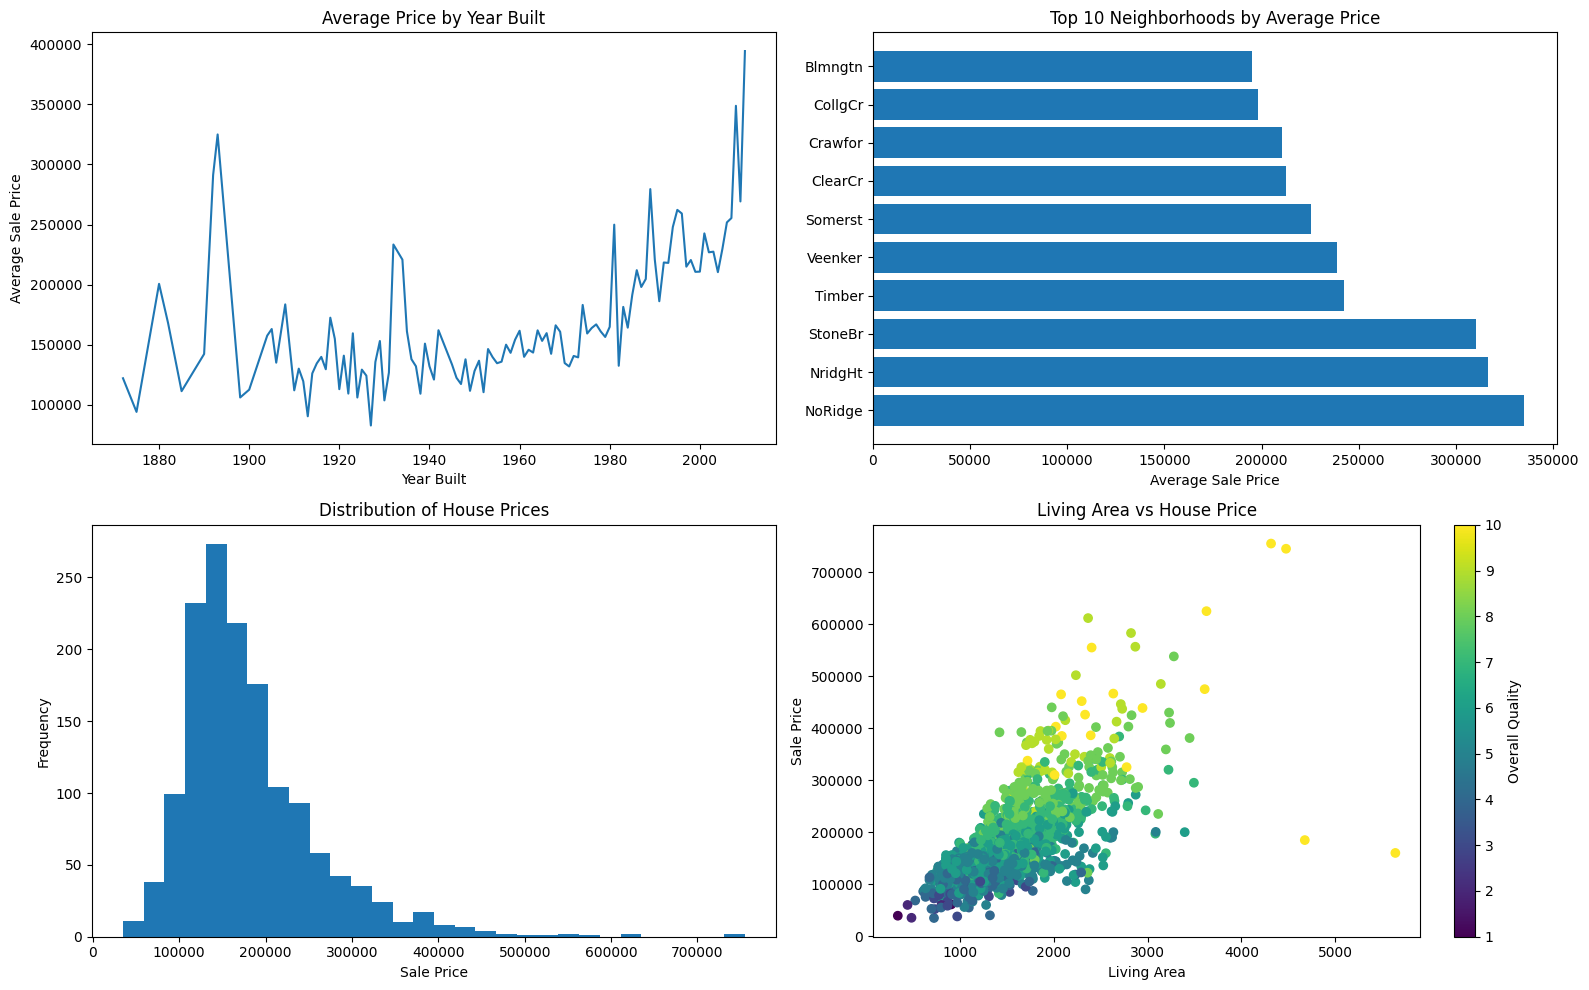

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Graph 1: Average price by construction year
year_price = df.groupby('YearBuilt')['SalePrice'].mean()

axes[0, 0].plot(year_price.index, year_price.values)
axes[0, 0].set_title("Average Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")

# Graph 2: Top 10 neighborhoods
neighborhood_price = df.groupby('Neighborhood')['SalePrice'].mean()
top_neighborhoods = neighborhood_price.sort_values(
    ascending=False
).head(10)

axes[0, 1].barh(top_neighborhoods.index, top_neighborhoods.values)
axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")

# Graph 3: House price distribution
axes[1, 0].hist(df['SalePrice'], bins=30)
axes[1, 0].set_title("Distribution of House Prices")
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].set_ylabel("Frequency")

# Graph 4: Living area vs house price
scatter = axes[1, 1].scatter(
    df['GrLivArea'],
    df['SalePrice'],
    c=df['OverallQual']
)

axes[1, 1].set_title("Living Area vs House Price")
axes[1, 1].set_xlabel("Living Area")
axes[1, 1].set_ylabel("Sale Price")

fig.colorbar(scatter, ax=axes[1, 1], label="Overall Quality")

plt.tight_layout()
plt.show()

In [44]:
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
from google.colab import files

files.download("eda_dashboard.png")

In this project, I performed Exploratory Data Analysis
(EDA) on the House Prices dataset using Python.

I used Pandas and NumPy for data analysis and
Matplotlib and Seaborn for data visualization.

During the analysis, I studied numerical and
categorical variables, calculated descriptive
statistics, and identified missing values and
outliers.

I also analyzed the relationship between house
prices, living area, overall quality, construction
year and neighborhood.

The visualizations showed that overall quality
and living area have positive relationships with
house prices. I also observed variations in house
prices across different neighborhoods.

Finally, I created a dashboard containing four
different visualizations to summarize my findings.

This project helped me understand how Exploratory
Data Analysis can be used to understand data,
identify patterns and discover useful insights.